# Load and inspect a ramp

This guide shows how to read a raw up-the-ramp datacube with
`~mercupix.ramp.RawRamp`, check its detector geometry, and look at frames and
pixel ramps.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 90

## A toy ramp

So that this page runs anywhere, we first simulate a small raw ramp and save it
in the *pyxim* format:

- 30 groups, 2.8 s apart,
- a 128 x 128 active area surrounded by 4 reference pixels on each side,
- 4 readout channels,
- a flat background, four stars (one of them saturating) and 30 cosmic rays,
- read noise, plus a per-channel and per-row offset that drifts from group to
  group and is also seen by the reference pixels.

The helper returns the truth (true flux map and cosmic rays), which other
guides use to check the results. With real data, skip this step.

In [2]:
import numpy as np
from astropy.io import fits

def make_toy_ramp(filename, ngroups=30, dt=2.8, size=128, nrefpixels=4, nchannels=4,
                  readnoise=10., bias=10_000., n_cosmics=30, seed=0):
    """Simulate a raw HxRG ramp in pyxim format and return the truth.

    The active area sees a flat background, a few stars (one of them
    saturating) and cosmic rays. All pixels, reference pixels included,
    share a per-channel and per-row offset that drifts from group to group.
    """
    rng = np.random.default_rng(seed)
    n = size + 2 * nrefpixels
    act = slice(nrefpixels, -nrefpixels)
    times = np.arange(1, ngroups + 1, dtype="float32") * dt

    # True flux [ADU/s] on the active area: background + stars.
    yy, xx = np.mgrid[:size, :size]
    flux = np.full((size, size), 5.)
    for y0, x0, amp in [(40, 40, 300.), (90, 30, 80.), (64, 100, 3_000.), (100, 90, 20.)]:
        flux += amp * np.exp(-((yy - y0)**2 + (xx - x0)**2) / (2 * 2.**2))

    # Accumulated photo-electrons (gain = 1) with Poisson noise.
    signal = np.zeros((ngroups, n, n))
    signal[:, act, act] = np.cumsum(rng.poisson(flux[None] * dt, (ngroups, size, size)), axis=0)

    # Cosmic rays: a jump that stays in the ramp from a random group onwards.
    cosmics = []
    for _ in range(n_cosmics):
        y, x, g = rng.integers(0, size), rng.integers(0, size), rng.integers(1, ngroups)
        amp = rng.uniform(300, 3_000)
        signal[g:, y + nrefpixels, x + nrefpixels] += amp
        cosmics.append((y, x, g, amp))

    # Correlated read noise seen by the reference pixels too.
    npix_channel = n // nchannels
    channel_offset = np.repeat(rng.normal(0, 30, (ngroups, nchannels)), npix_channel, axis=1)
    row_offset = rng.normal(0, 5, (ngroups, n))
    raw = (bias + signal + channel_offset[:, None, :] + row_offset[:, :, None]
           + rng.normal(0, readnoise, signal.shape))
    raw = np.clip(raw, 0, 65_535).astype("uint16")

    primary = fits.PrimaryHDU(raw)
    primary.header["NCHAN"] = nchannels
    table = fits.BinTableHDU.from_columns([fits.Column("readout_times", "E", array=times)])
    fits.HDUList([primary, table]).writeto(filename, overwrite=True)
    return dict(flux=flux, cosmics=cosmics, times=times, readnoise=readnoise)

In [3]:
truth = make_toy_ramp("toy_ramp.fits")

## Load the ramp

`~mercupix.baseramp.BaseRamp.from_filename` reads the datacube, the group times
and the number of channels. Set `datatype` to the format of your file:

| `datatype` | Format |
|---|---|
| `"pyxim"` | pyxim simulations (FITS) |
| `"roman"` | Roman flight-like data (FITS) |
| `"ip2i"` | IP2I test bench (HDF5) |
| `None` | any FITS file (data of the primary HDU, no times) |

In [4]:
from mercupix.ramp import RawRamp

ramp = RawRamp.from_filename("toy_ramp.fits", datatype="pyxim")
ramp

## Detector geometry

The ramp keeps the full frames, reference pixels included. The active area is
`2 * nrefpixels` smaller in each direction, and `actslice` selects it.

In [5]:
print("cube shape       :", ramp.cube_shape)
print("active shape     :", ramp.active_shape)
print("reference pixels :", ramp.nrefpixels)
print("channels         :", ramp.nchannels, "x", ramp.npix_per_channel, "columns")
print("first times [s]  :", ramp.times[:4])

cube shape       : (30, 136, 136)
active shape     : [128 128]
reference pixels : 4
channels         : 4 x 34 columns
first times [s]  : [ 2.8  5.6  8.4 11.2]


## Look at a frame

`~mercupix.baseramp.BaseRamp.show_frame` displays one group with
percentile-based color limits. Without any correction, the read noise is
dominated by the offsets of the readout channels, which show up as vertical
bands.

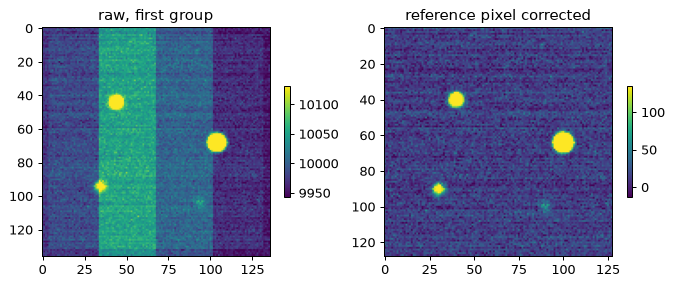

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ramp.show_frame(frame_num=0, ax=axes[0])
axes[0].set_title("raw, first group")
ramp.show_frame(frame_num=0, corr_refpix=True, ax=axes[1])
axes[1].set_title("reference pixel corrected")
plt.show()

## Look at pixel ramps

`~mercupix.baseramp.BaseRamp.show_pixramp` plots the ramp of one or several
pixels against time. Here we show a pixel on a star, a background pixel, and a
pixel hit by a cosmic ray. The indices refer to the full frame, so we add
`nrefpixels` to the active-area coordinates.

cosmic ray at (7, 55), group 9, 1903 ADU


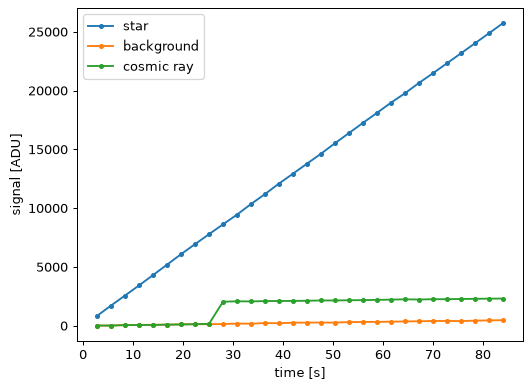

In [7]:
y, x, g, amp = next(c for c in truth["cosmics"] if 8 <= c[2] <= 20)
print(f"cosmic ray at ({y}, {x}), group {g}, {amp:.0f} ADU")

pixels = [[40, 10, y], [40, 10, x]]   # active-area coordinates
fig, ax = ramp.show_pixramp(pixel_ids=pixels, corr_refpix=True, marker=".")
ax.legend(["star", "background", "cosmic ray"])
ax.set_xlabel("time [s]")
ax.set_ylabel("signal [ADU]")
plt.show()

Next: {doc}`howto_preprocess`.